In [ ]:
import pandas as pd
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile

URL = "https://archive.ics.uci.edu/static/public/" "222/bank+marketing.zip"
outer = ZipFile(BytesIO(urlopen(URL).read()))
inner = ZipFile(BytesIO(outer.read("bank-additional.zip")))
df = pd.read_csv(inner.open("bank-additional/bank-additional.csv"), sep=";")
print(df.shape)

X = df.drop(columns=["duration", "y"])

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)


def metrics(X_test, y_test, model):
    y_pred = model.predict(X_test)
    y_probs = model.predict_proba(X_test)[:, 1]

    result = {
        "Accuracy": round(accuracy_score(y_test, y_pred), 2),
        "Precision": round(precision_score(y_test, y_pred), 2),
        "Recall": round(recall_score(y_test, y_pred), 2),
        "F1 Score": round(f1_score(y_test, y_pred), 2),
        "ROC AUC": round(roc_auc_score(y_test, y_probs), 2),
    }

    return pd.DataFrame(result, index=[0])

In [ ]:
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split

y = df["y"].map({"no": 0, "yes": 1})
X = pd.get_dummies(X, drop_first=True, dtype=int)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

model = XGBClassifier(
    n_estimators=700,
    learning_rate=0.1,
    max_depth=5,
    eval_metric="logloss",
    early_stopping_rounds=20,
    random_state=42,
)

model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)

print(model.score(X_val, y_val))
metrics(X_test, y_test, model)

In [ ]:
print(f"Best iteration -> {model.best_iteration}")
print(f"Best score -> {model.best_score}")

In [ ]:
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Train / Validation / Test split
X_tmp, X_test, y_tmp, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

X_train, X_valid, y_train, y_valid = train_test_split(
    X_tmp, y_tmp, test_size=0.2, stratify=y_tmp, random_state=42
)


# Training function
def train(lr, patience=50):

    model = XGBClassifier(
        n_estimators=2000,
        learning_rate=lr,
        max_depth=3,
        eval_metric="logloss",
        early_stopping_rounds=patience,
        random_state=42,
    )

    model.fit(
        X_train,
        y_train,
        eval_set=[(X_train, y_train), (X_valid, y_valid)],
        verbose=False,
    )

    return model

In [ ]:
models = {}

for lr in (0.3, 0.05):

    m = train(lr)

    acc = accuracy_score(y_test, m.predict(X_test))

    print(
        f"lr={lr}: "
        f"best_iteration={m.best_iteration}, "
        f"best_score={m.best_score:.4f}, "
        f"test_acc={acc:.4f}"
    )

    models[lr] = m


model = models[0.05]

In [ ]:
import matplotlib.pyplot as plt

res = model.evals_result()
plt.plot(res["validation_0"]["logloss"], label="train")
plt.plot(res["validation_1"]["logloss"], label="valid")
plt.axvline(model.best_iteration, ls="--", color="gray")
plt.xlabel("Boosting round")
plt.ylabel("logloss")
plt.legend()
plt.show()

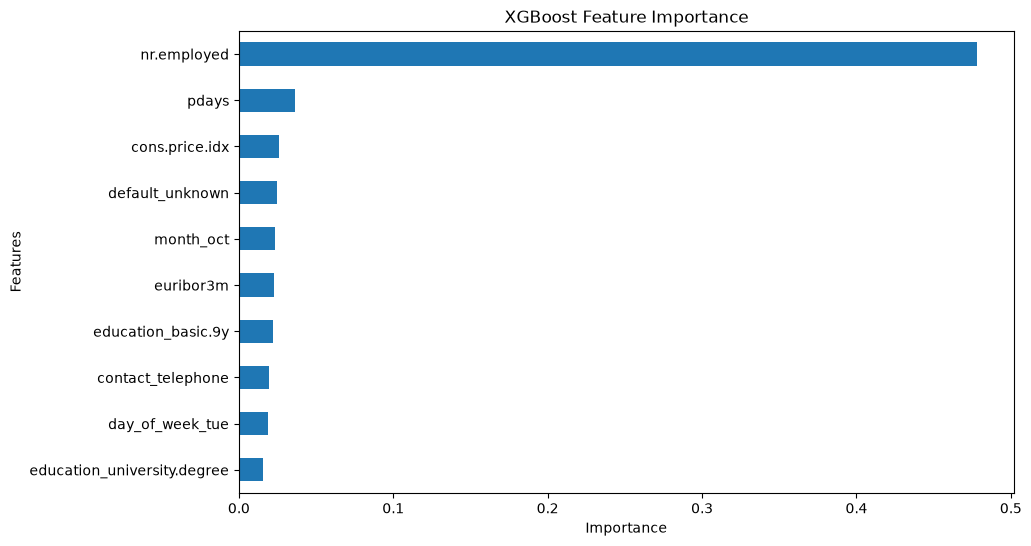

In [53]:
feature_importance = pd.Series(
    model.feature_importances_, index=X_train.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 6))

feature_importance.head(10).plot(kind="barh")

plt.title("XGBoost Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.gca().invert_yaxis()

plt.show()